## Question 5
Un abonné annuel sur cinq ne renouvelle pas. Au bout de combien de temps et à quels signes peut-on le repérer ?

**Charger le fichier**
- Ce que ça fait : charge le fichier abonnés dans un tableau df, affiche sa taille (500 lignes, 7 colonnes) et le type de chaque colonne.
- Résultat : 500 abonnés, aucune valeur manquante ; float64 = nombres à virgule, int64 = entiers, object = texte.
- Pour l'oral : une cellule n'affiche automatiquement que sa dernière ligne, c'est pour ça que df.head() ne s'affichait pas.

In [13]:
import pandas as pd 

df = pd.read_csv("data/Citycycle_abonnes.csv")
print(df.shape)   # nombre de lignes et de colonnes : on attend (500, 7)
df.head()         
df.info()         # le type de chaque colonne : nombres ou texte ?

(500, 7)
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   abonne_id           500 non-null    str    
 1   anciennete_mois     500 non-null    float64
 2   trajets_par_mois    500 non-null    float64
 3   distance_moy_km     500 non-null    float64
 4   incidents_signales  500 non-null    int64  
 5   formule             500 non-null    str    
 6   a_renouvele         500 non-null    str    
dtypes: float64(3), int64(1), str(3)
memory usage: 27.5 KB


**Valeurs manquantes et doublons**
- Ce que ça fait : compte les cases vides par colonne, les lignes entièrement identiques, puis les identifiants présents deux fois.
- Résultat : 0 partout.
- Pour l'oral : on teste l'identifiant à part, car deux lignes peuvent concerner le même abonné tout en différant d'une seule valeur ; duplicated() ne les verrait pas.

In [14]:
print(df.isna().sum())                     # Valeur manquentes par colonne 
print(df.duplicated().sum())               # Lignes entierement indentiques 
print(df["abonne_id"].duplicated().sum())  # Meme abonee present 2 fois

abonne_id             0
anciennete_mois       0
trajets_par_mois      0
distance_moy_km       0
incidents_signales    0
formule               0
a_renouvele           0
dtype: int64
0
0


**Résumé des colonnes**
- Ce que ça fait : donne minimum, maximum, moyenne et quartiles des colonnes numériques, et le nombre de lignes par valeur pour les colonnes texte.
- Résultat : 360 annuels, 140 mensuels ; 385 renouvellements, 115 départs ; la plupart des abonnés ont 0 ou 1 incident.
- Pour l'oral : le cours dit que Q1 et Q3 disent où vivent les clients, alors que min et max disent seulement jusqu'où va le fichier.

In [15]:
df.describe()   # minimum, maximum et moyenne de chaque colonne numérique

print(df["formule"].value_counts())
print(df["a_renouvele"].value_counts())
print(df["incidents_signales"].value_counts())

formule
annuel     360
mensuel    140
Name: count, dtype: int64
a_renouvele
oui    385
non    115
Name: count, dtype: int64
incidents_signales
0    306
1    149
2     41
3      4
Name: count, dtype: int64


**Valeurs impossibles et unités**
- Ce que ça fait : compte les valeurs qui violent une règle de bon sens : ancienneté nulle ou négative, trajets négatifs, distance nulle, ancienneté de plus de 120 mois (10 ans).
- Résultat : 0 partout.
- Pour l'oral : une distance de 0,3 à 5,7 km est cohérente avec du vélo en ville ; si le maximum avait été 3 000, la colonne aurait été en mètres.


In [16]:
print((df["anciennete_mois"] <= 0).sum())    #anciennete null ou negative (impossible)
print((df["trajets_par_mois"] < 0).sum())
print((df["distance_moy_km"]<= 0).sum())
print((df["anciennete_mois"] > 120).sum())   #plus de 10 ans (suspect)

0
0
0
0


**La cible et les abonnés annuels**
- Ce que ça fait : crée une colonne qui vaut 1 si l'abonné n'a pas renouvelé, 0 sinon, puis ne garde que les annuels.
- Résultat : 360 annuels, 21,7 % de départs : le « un sur cinq » de l'énoncé.
- Pour l'oral : on écarte les mensuels parce que la question vise les annuels, et que renouveler n'a pas le même sens pour un mensuel. .copy() évite que modifier annuels touche aussi df.

In [17]:
# Cible en 0/1 : 1 = n'a pas renouvelé (c'est l'événement qu'on cherche à prédire)
df["depart"] = (df["a_renouvele"] == "non").astype(int)

# On garde les abonnés annuels uniquement
annuels = df[df["formule"] == "annuel"].copy()
print(len(annuels), annuels["depart"].mean())   # on attend 360 abonnés et environ 0.217


360 0.21666666666666667


Verificarion du fichier abonnes
- 500 lignes, aucune valeur manquante, aucun doublon. Valeurs plausibles et unités cohérentes : ancienneté de 1 à 60 mois, distance de 0,3 à 5,7 km. Aucune correction nécessaire. 


**Moyennes selon la cible**
- Ce que ça fait : sépare partants (1) et fidèles (0), et affiche la moyenne de chaque variable dans chaque groupe.
- Résultat : les partants sont plus récents (19 contre 23 mois), roulent moins (7,4 contre 9,9 trajets) et signalent plus d'incidents (0,65 contre 0,40) ; la distance est identique.
- Pour l'oral : c'est « le geste le plus rentable de l'exploration » selon le cours.

In [18]:
variables = ["anciennete_mois", "trajets_par_mois", "distance_moy_km", "incidents_signales"]
print(annuels.groupby("depart")[variables].mean())

        anciennete_mois  trajets_par_mois  distance_moy_km  incidents_signales
depart                                                                        
0             22.634752          9.854610         2.671348            0.400709
1             19.358974          7.435897         2.756795            0.653846


**Taux de départ par tranche d'ancienneté**
- Ce que ça fait : découpe l'ancienneté en tranches, puis donne pour chacune le taux de départ (mean) et le nombre d'abonnés (size).
- Résultat : 23 à 27 % de départs pendant deux ans, puis 11 % après 3 ans.
- Pour l'oral : comme depart vaut 0 ou 1, sa moyenne est directement un taux. Dans (0, 6], la parenthèse exclut 0 et le crochet inclut 6. observed=False supprime juste un avertissement de pandas.

In [19]:
tranches = pd.cut(annuels["anciennete_mois"], [0,6,12,18,24,36,60])
print(annuels.groupby(tranches, observed=False)["depart"].agg(["mean", "size"]))

                     mean  size
anciennete_mois                
(0, 6]           0.241379    29
(6, 12]          0.267606    71
(12, 18]         0.242857    70
(18, 24]         0.227273    66
(24, 36]         0.205882    68
(36, 60]         0.107143    56


**Trajets et incidents**
- Résultat : 31 % de départs à 3 trajets ou moins, contre 11 % au-delà de 15 ; 18 % sans incident, 50 % avec deux incidents.
- Pour l'oral : avec 3 incidents, il n'y a que 3 abonnés : trop peu pour conclure. Les bornes s'arrêtent à 40 car le maximum du fichier est 38.

In [20]:
t = pd.cut(annuels["trajets_par_mois"], [0, 3, 6, 10, 15, 40])
print(annuels.groupby(t, observed=False)["depart"].agg(["mean", "size"]))
print(annuels.groupby("incidents_signales")["depart"].agg(["mean", "size"]))

                      mean  size
trajets_par_mois                
(0, 3]            0.306452    62
(3, 6]            0.244186    86
(6, 10]           0.218391    87
(10, 15]          0.188406    69
(15, 40]          0.107143    56
                        mean  size
incidents_signales                
0                   0.181416   226
1                   0.224299   107
2                   0.500000    24
3                   0.333333     3


**Q5 – Conclusions (abonnés annuels)**

- Quand : le risque de départ reste entre 23 et 27 % pendant les deux premières années, puis tombe à 11 % après 3 ans.
- Signe 1, l’usage : 31 % de départs à 3 trajets par mois ou moins, contre 11 % au-delà de 15.
- Signe 2, les incidents : 18 % de départs sans incident, 50 % avec deux incidents (24 abonnés). Avec 3 incidents, il n’y a que 3 abonnés : trop peu pour conclure.
- La distance moyenne ne distingue pas les deux groupes.

## Question 6
Combien d'abonnés faudrait-il solliciter pour en retenir la moitié, et à partir de quel coût ça ne vaut plus le coup ?

**Choisir k par validation croisée**
- Ce que ça fait : pour chaque k, coupe les 360 annuels en 5 paquets ; chaque paquet sert une fois de test, et on affiche l'AUC moyenne et son écart-type.
- Résultat : meilleur score à k = 51, AUC = 0,63, écart-type d'environ 0,1.
- Pourquoi ces choix :
    - les k plus proches voisins : méthode de classification vue en cours ;
    - StandardScaler : des mois et des incidents n'ont pas la même échelle, et la distance les additionne ;
    - make_pipeline : la standardisation est refaite à chaque tour sur les seules données d'apprentissage, sans fuite ;
    - StratifiedKFold : garde 22 % de départs dans chaque paquet ;
    - l'AUC plutôt que la justesse : dire « reste » à tout le monde donnerait déjà 78 % de bonnes réponses.
- Pour l'oral : k = 51 signifie que le modèle regarde les 51 abonnés les plus ressemblants. Une AUC de 0,63 signifie qu'il place un partant au-dessus d'un fidèle dans 63 % des cas ; 0,5 serait du hasard. Le modèle est modeste, et il faut le dire.

In [21]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

X = annuels[["anciennete_mois", "trajets_par_mois", "incidents_signales"]]
y = annuels["depart"]

cv = StratifiedKFold(5, shuffle=True, random_state=42)

for k in [51, 71, 101, 151]:
    modele = make_pipeline(StandardScaler(), KNeighborsClassifier(k))
    score = cross_val_score(modele, X, y, cv=cv, scoring="roc_auc")
    print(k, round(score.mean(), 3), round(score.std(), 3))

51 0.629 0.111
71 0.61 0.099
101 0.603 0.072
151 0.608 0.081


**Risque de chaque abonné et nombre à contacter**
- Ce que ça fait : donne à chaque abonné un risque estimé par un modèle qui ne l'a pas vu pendant l'apprentissage, trie du plus risqué au moins risqué, puis cumule la part des partants touchés.
- Résultat : 119 abonnés sur 360 suffisent pour toucher la moitié des partants, contre 180 au hasard.
- Pour l'oral : toucher la moitié des partants n'est pas en retenir la moitié ; il faudrait que chaque relance réussisse, c'est une hypothèse du calcul de rentabilité.

In [22]:
from sklearn.model_selection import cross_val_predict

modele = make_pipeline(StandardScaler(), KNeighborsClassifier(51))
annuels["risque"] = cross_val_predict(modele, X, y, cv=cv, method="predict_proba")[:,1]

classes = annuels.sort_values("risque", ascending=False)
classes["partants_cumules"] = classes["depart"].cumsum() / classes["depart"].sum()

n = (classes["partants_cumules"] < 0.5).sum() + 1 
print(n, "abonnes a contacter sur", len(classes)) 

119 abonnes a contacter sur 360


**Courbe de gain**
- Ce que ça fait : trace la part des partants touchés selon la part des abonnés contactés.
- Lecture : la courbe bleue, c'est le modèle ; la diagonale, c'est le hasard ; la ligne grise, c'est le seuil des 50 %.
- Pour l'oral : plus la courbe bleue passe au-dessus de la diagonale, plus le modèle est utile. C'est le graphique à mettre dans les slides.

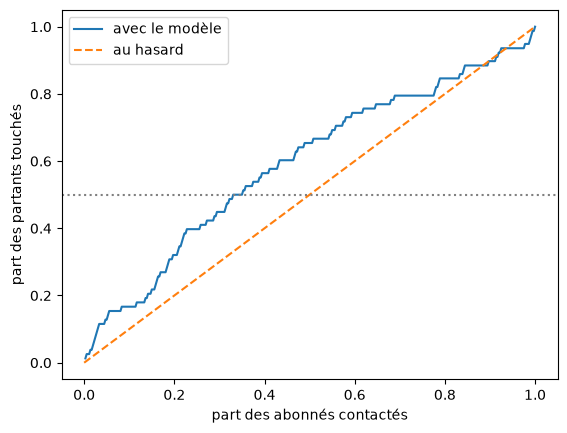

In [23]:
import matplotlib.pyplot as plt
import numpy as np 

part_contactes = np.arange(1, len(classes) + 1) / len(classes)

plt.plot(part_contactes, classes["partants_cumules"], label="avec le modèle")
plt.plot([0, 1], [0, 1], "--", label="au hasard")
plt.axhline(0.5, color="grey", linestyle=":")
plt.xlabel("part des abonnés contactés")
plt.ylabel("part des partants touchés")
plt.legend()
plt.show()

In [24]:
prix_abonnement = 40
taux_reussite = 0.5

contactes = 119
partants_touches = int(classes["depart"].head(contactes).sum())
retenus = partants_touches * taux_reussite 

cout_max = retenus* prix_abonnement / contactes
print(partants_touches, "partants touchés,", retenus, "retenus")
print("Coût maximal par contact :", round(cout_max, 2), "€")

39 partants touchés, 19.5 retenus
Coût maximal par contact : 6.55 €
